In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage


In [2]:

# Load the customer dataset
df = pd.read_csv("Mall_Customers.csv")

# Display the first five rows
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:

# Select features for Experiment 1
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Display first five standardized rows
print(X_scaled[:5])


[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


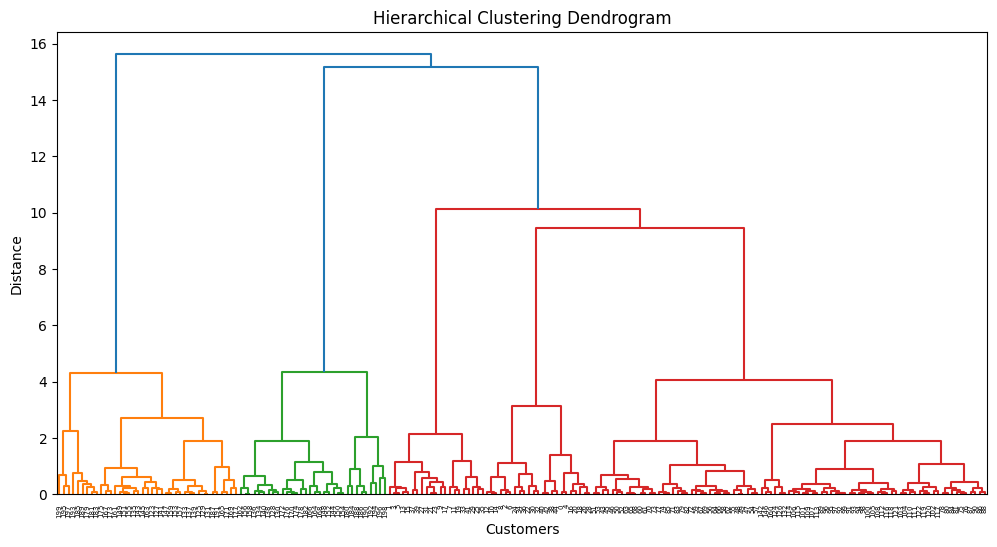

In [4]:

# Create hierarchical clustering using Ward linkage
linked = linkage(X_scaled, method="ward")

# Plot the dendrogram
plt.figure(figsize=(12, 6))
dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()


In [5]:

# Apply Hierarchical Clustering with 5 clusters
hc = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

# Assign each customer to a cluster
clusters = hc.fit_predict(X_scaled)

# Add cluster labels to the dataset
df["Hierarchical_Cluster"] = clusters

# Display number of customers in each cluster
print(df["Hierarchical_Cluster"].value_counts().sort_index())


Hierarchical_Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


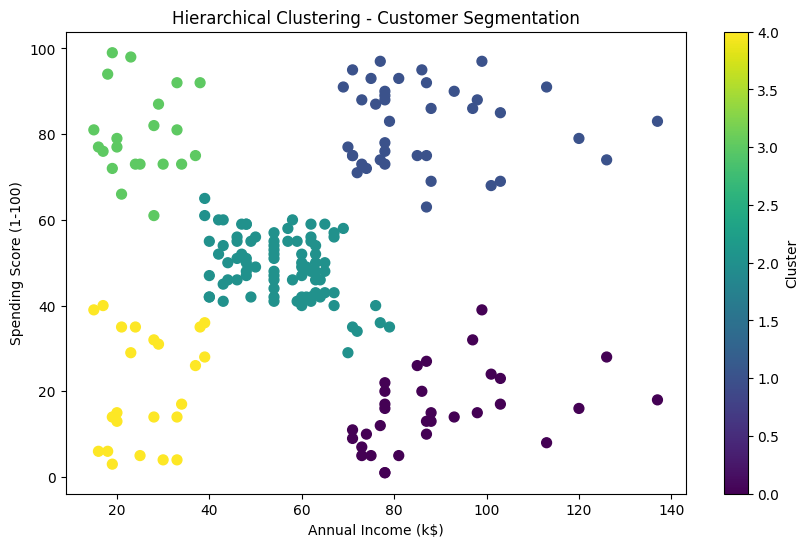

In [6]:

# Plot customer clusters
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Hierarchical_Cluster"],
    cmap="viridis",
    s=50
)

plt.title("Hierarchical Clustering - Customer Segmentation")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.colorbar(label="Cluster")
plt.show()


In [7]:

score = silhouette_score(X_scaled, clusters)

print("Hierarchical Clustering Silhouette Score:", round(score, 4))


Hierarchical Clustering Silhouette Score: 0.5538


In [8]:

# Save customer data with hierarchical cluster labels
df.to_csv("hierarchical_exp1_result.csv", index=False)

print("Hierarchical clustering results saved successfully!")


Hierarchical clustering results saved successfully!
